# 21 · Sensibilidad del bootstrap por bloques (7, 14 y 30 días)

**Objetivo:** comprobar si las conclusiones del notebook 20 cambian al modificar la longitud del bloque temporal. **No entrena ningún modelo.** Compara el diferencial pareado de errores cuadráticos entre cada modelo y persistencia, para cada horizonte exacto. Se incluyen SARIMAX con y sin semana, LSTM, TFT y GRU.

**Importante:** los intervalos bootstrap son exploratorios; no son pruebas formales de superioridad ni corrigen comparaciones múltiples. Los orígenes consecutivos generan errores correlacionados, especialmente para horizontes largos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_root():
    for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (p/'reports'/'comparacion_definitiva_horizontes_exactos'/'predicciones_todos.parquet').exists():
            return p
    raise FileNotFoundError('No encuentro predicciones_todos.parquet. Abre el notebook dentro de tesis-bolsa.')
ROOT=find_root()
SRC=ROOT/'reports'/'comparacion_definitiva_horizontes_exactos'/'predicciones_todos.parquet'
OUT=ROOT/'reports'/'sensibilidad_bootstrap_bloques'
OUT.mkdir(parents=True,exist_ok=True)
raw=pd.read_parquet(SRC)
print('Archivo:',SRC,'| Filas:',len(raw),'| Salidas:',OUT)

Archivo: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_definitiva_horizontes_exactos/predicciones_todos.parquet | Filas: 47385 | Salidas: /Users/maguverm/Documents/tesis-bolsa/reports/sensibilidad_bootstrap_bloques


## 1. Validar horizontes, orígenes y datos pareados

Si algo no coincide, el análisis se detiene para evitar comparar errores de fechas distintas.

In [2]:
needed={'Modelo','Horizonte','origen','fecha','real','pred'}
assert needed.issubset(raw.columns), f'Faltan columnas: {needed-set(raw.columns)}'
models=['SARIMAX','SARIMAX sin semana','LSTM cuantílica','TFT + covariables','GRU Bayesiana']
reference='Persistencia'
assert set(models+[reference]).issubset(set(raw.Modelo.unique())), 'Faltan modelos o persistencia'
df=raw[raw.Modelo.isin(models+[reference])].copy()
df['origen']=pd.to_datetime(df.origen);df['fecha']=pd.to_datetime(df.fecha)
df['Horizonte']=df.Horizonte.astype(int)
assert not df.duplicated(['Modelo','Horizonte','origen']).any(), 'Predicciones duplicadas'
assert ((df.fecha-df.origen).dt.days==df.Horizonte).all(), 'Fechas mal alineadas'
assert df[['real','pred']].notna().all().all(), 'Datos faltantes'
assert np.isfinite(df[['real','pred']].to_numpy(float)).all(), 'Datos no finitos'
assert set(df.Horizonte.unique())==set(range(1,16)), 'Horizontes distintos de 1–15'
paired={}
for h in range(1,16):
    g=df[df.Horizonte==h]
    p=g.pivot(index='origen',columns='Modelo',values='pred').sort_index()
    y=g.pivot(index='origen',columns='Modelo',values='real').reindex(index=p.index,columns=p.columns)
    f=g.pivot(index='origen',columns='Modelo',values='fecha').reindex(index=p.index,columns=p.columns)
    assert p.notna().all().all() and y.notna().all().all(), f'Faltan pares en h={h}'
    assert len(p)==g.groupby('Modelo').size().iloc[0], f'Conteos diferentes en h={h}'
    assert np.allclose(y.to_numpy(float),y.iloc[:,[0]].to_numpy(float)), f'Reales distintos h={h}'
    assert (f.eq(f.iloc[:,0],axis=0)).all().all(), f'Fechas distintas h={h}'
    squared=(p-y)**2
    paired[h]=squared
print('Validado: 15 horizontes; modelos:',', '.join(models))
print('Orígenes por horizonte:',{h:len(p) for h,p in paired.items()})

Validado: 15 horizontes; modelos: SARIMAX, SARIMAX sin semana, LSTM cuantílica, TFT + covariables, GRU Bayesiana
Orígenes por horizonte: {1: 351, 2: 351, 3: 351, 4: 351, 5: 351, 6: 351, 7: 351, 8: 351, 9: 351, 10: 351, 11: 351, 12: 351, 13: 351, 14: 351, 15: 351}


## 2. Bootstrap circular de bloques móviles

Para cada horizonte se conserva la misma muestra de orígenes para todos los modelos, preservando el carácter pareado. En cada réplica se extraen bloques consecutivos de longitud **7, 14 o 30**, con inicio aleatorio y envolvimiento circular. Se calcula el promedio de `error_modelo² − error_persistencia²`.

- Intervalo totalmente negativo: mejora exploratoria.
- Intervalo totalmente positivo: empeora exploratoriamente.
- Intervalo que incluye cero: no concluyente.

Se utiliza una semilla reproducible y **2.000 réplicas** por longitud de bloque.

In [3]:
BLOCKS=[7,14,30]
B=2000
rng=np.random.default_rng(20261010)
rows=[]
for h, sq in paired.items():
    n=len(sq)
    d=sq[models].to_numpy(float)-sq[[reference]].to_numpy(float)
    for block in BLOCKS:
        reps=np.empty((B,len(models)),dtype=float)
        count=int(np.ceil(n/block))
        offsets=np.arange(block)
        for b in range(B):
            starts=rng.integers(0,n,size=count)
            idx=((starts[:,None]+offsets[None,:])%n).ravel()[:n]
            reps[b]=d[idx].mean(axis=0)
        lows=np.quantile(reps,.025,axis=0)
        highs=np.quantile(reps,.975,axis=0)
        obs=d.mean(axis=0)
        for j,m in enumerate(models):
            status='mejora' if highs[j]<0 else ('empeora' if lows[j]>0 else 'no concluyente')
            rmse=np.sqrt(sq[m].mean())
            rmse_ref=np.sqrt(sq[reference].mean())
            rows.append({'Horizonte':h,'Modelo':m,'Bloque':block,'N_origenes':n,
                         'RMSE_modelo':rmse,'RMSE_persistencia':rmse_ref,
                         'Skill_RMSE_pct':100*(1-rmse/rmse_ref),
                         'Delta_MSE':obs[j],'IC95_inf':lows[j],'IC95_sup':highs[j],
                         'Lectura':status})
res=pd.DataFrame(rows)
res.to_csv(OUT/'sensibilidad_bootstrap_7_14_30.csv',index=False)
print('Resultados guardados:',len(res),'filas')
display(res[res.Horizonte.isin([1,3,5,7,10,14,15])].round(2))

Resultados guardados: 225 filas


,Horizonte,Modelo,Bloque,N_origenes,RMSE_modelo,RMSE_persistencia,Skill_RMSE_pct,Delta_MSE,IC95_inf,IC95_sup,Lectura
0,1,SARIMAX,7,351,55.95,55.57,-0.68,42.39,-176.96,326.01,no concluyente
1,1,SARIMAX sin semana,7,351,56.66,55.57,-1.95,121.78,-111.12,426.27,no concluyente
2,1,LSTM cuantílica,7,351,55.15,55.57,0.76,-46.52,-134.53,34.90,no concluyente
3,1,TFT + covariables,7,351,53.65,55.57,3.46,-209.95,-570.07,100.56,no concluyente
4,1,GRU Bayesiana,7,351,55.01,55.57,1.01,-61.94,-238.71,119.16,no concluyente
...,...,...,...,...,...,...,...,...,...,...,...
220,15,SARIMAX,30,351,173.83,167.72,-3.65,2088.10,-2795.48,8023.80,no concluyente
221,15,SARIMAX sin semana,30,351,171.59,167.72,-2.31,1315.09,-3355.69,6909.87,no concluyente
222,15,LSTM cuantílica,30,351,161.28,167.72,3.84,-2117.68,-9004.28,5259.59,no concluyente
223,15,TFT + covariables,30,351,225.39,167.72,-34.38,22670.13,4795.24,51014.81,empeora


## 3. ¿Cambian las conclusiones cuando cambia el bloque?

In [4]:
pivot=res.pivot_table(index=['Horizonte','Modelo'],columns='Bloque',values='Lectura',aggfunc='first').reset_index()
pivot.columns=['Horizonte','Modelo','Bloque_7','Bloque_14','Bloque_30']
cols=['Bloque_7','Bloque_14','Bloque_30']
pivot['Robustez']=np.where(pivot[cols].nunique(axis=1)==1,'estable','sensible al bloque')
pivot.to_csv(OUT/'consistencia_lecturas.csv',index=False)
print('Distribución de estabilidad:')
print(pivot.Robustez.value_counts().to_string())
print('\nResultados que cambian según longitud del bloque:')
display(pivot[pivot.Robustez=='sensible al bloque'])
print('\nLSTM en horizontes 7–15:')
display(pivot[(pivot.Modelo=='LSTM cuantílica') & (pivot.Horizonte>=7)])

Distribución de estabilidad:
Robustez
estable    75

Resultados que cambian según longitud del bloque:


,Horizonte,Modelo,Bloque_7,Bloque_14,Bloque_30,Robustez



LSTM en horizontes 7–15:


,Horizonte,Modelo,Bloque_7,Bloque_14,Bloque_30,Robustez
31,7,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
36,8,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
41,9,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
46,10,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
51,11,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
56,12,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
61,13,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
66,14,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
71,15,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable


## 4. Gráficos de sensibilidad para horizontes clave

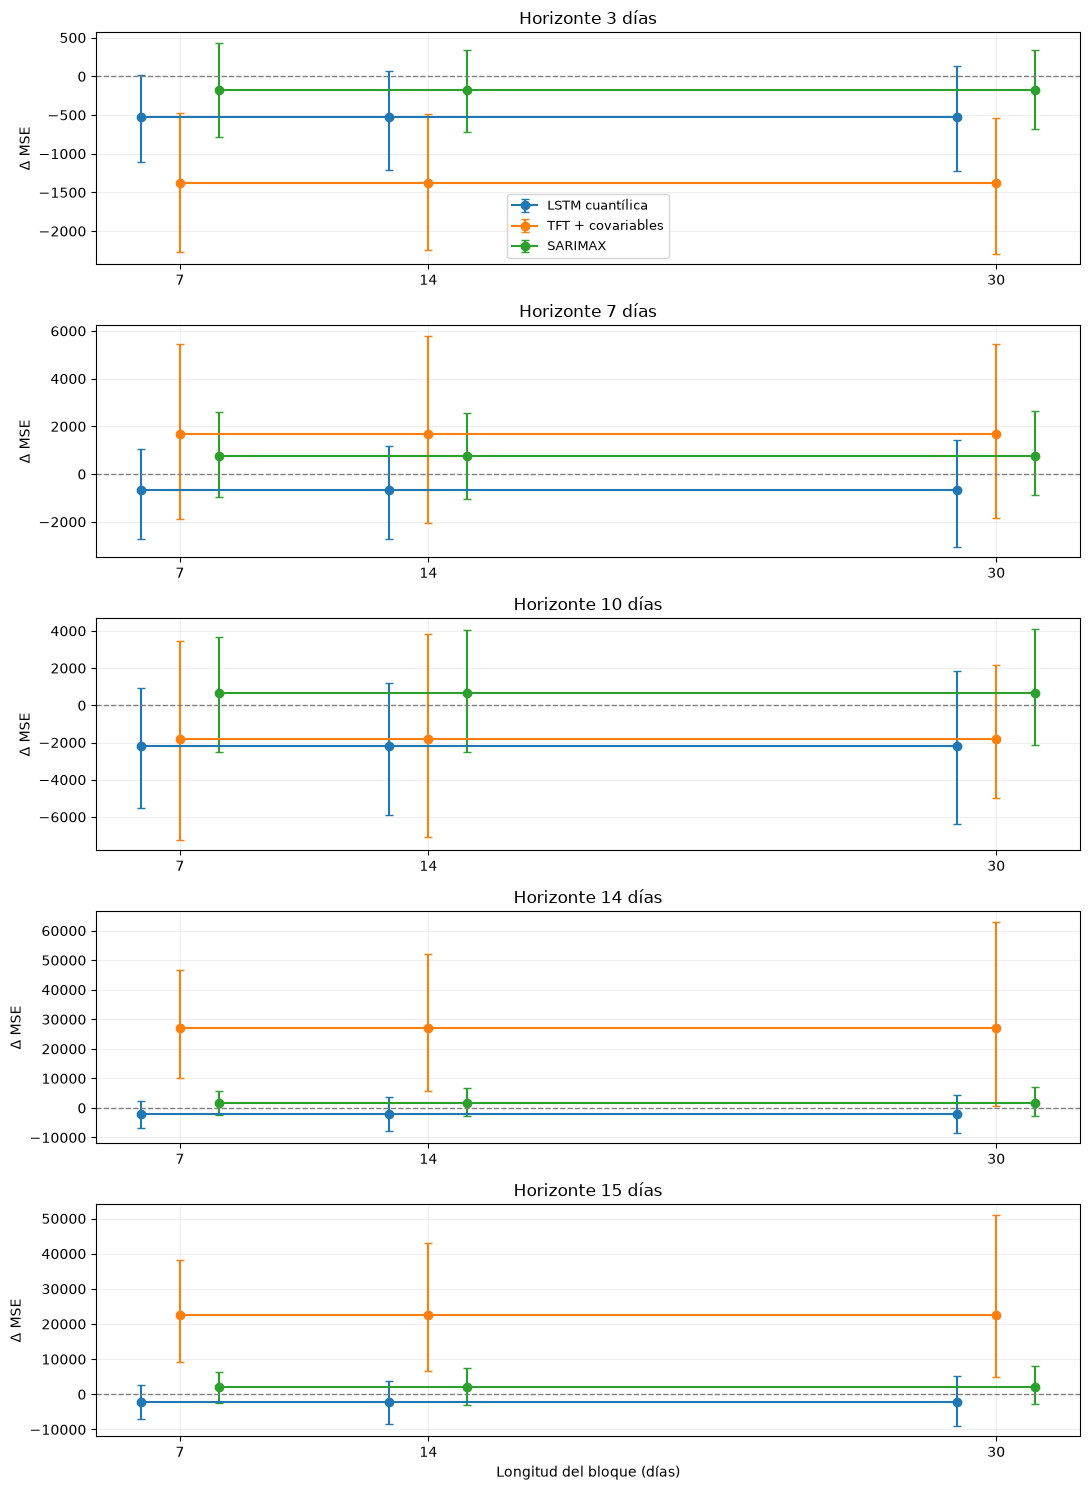

In [5]:
selected=[3,7,10,14,15]
fig,axs=plt.subplots(len(selected),1,figsize=(11,15),sharex=False)
for ax,h in zip(axs,selected):
    z=res[(res.Horizonte==h)&(res.Modelo.isin(['LSTM cuantílica','TFT + covariables','SARIMAX']))]
    for j,m in enumerate(['LSTM cuantílica','TFT + covariables','SARIMAX']):
        q=z[z.Modelo==m].sort_values('Bloque')
        xx=np.array(BLOCKS,dtype=float)+(j-1)*1.1
        ax.errorbar(xx,q.Delta_MSE,yerr=[q.Delta_MSE-q.IC95_inf,q.IC95_sup-q.Delta_MSE],fmt='o-',capsize=3,label=m)
    ax.axhline(0,linestyle='--',linewidth=1,color='gray')
    ax.set_xticks(BLOCKS)
    ax.set_ylabel('Δ MSE')
    ax.set_title(f'Horizonte {h} días')
    ax.grid(alpha=.2)
axs[0].legend(loc='best',fontsize=9)
axs[-1].set_xlabel('Longitud del bloque (días)')
fig.tight_layout()
fig.savefig(OUT/'sensibilidad_intervalos.png',dpi=160,bbox_inches='tight')
plt.show()

## 5. Resumen automático y advertencias para la tesis

In [6]:
key=pivot[(pivot.Modelo.isin(['LSTM cuantílica','TFT + covariables','SARIMAX'])) & (pivot.Horizonte.isin([3,5,7,10,14,15]))]
display(key)
print('Interpretación:')
print('- Una lectura estable no equivale a prueba de significancia formal.')
print('- El bootstrap circular por bloques es una aproximación; bloques de 7, 14 y 30 días sirven como sensibilidad.')
print('- Se realizan múltiples comparaciones entre modelos y horizontes, sin ajuste por multiplicidad.')
print('- El análisis evalúa errores puntuales; NO revalida cobertura probabilística ni prueba ausencia de fuga de información en entrenamiento.')
print('- Para inferencia confirmatoria, preespecificar contrastes y considerar procedimientos robustos a dependencia temporal.')
print('\nArchivos creados en:',OUT)

,Horizonte,Modelo,Bloque_7,Bloque_14,Bloque_30,Robustez
11,3,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
12,3,SARIMAX,no concluyente,no concluyente,no concluyente,estable
14,3,TFT + covariables,mejora,mejora,mejora,estable
21,5,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
22,5,SARIMAX,no concluyente,no concluyente,no concluyente,estable
24,5,TFT + covariables,mejora,mejora,mejora,estable
31,7,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable
32,7,SARIMAX,no concluyente,no concluyente,no concluyente,estable
34,7,TFT + covariables,no concluyente,no concluyente,no concluyente,estable
46,10,LSTM cuantílica,no concluyente,no concluyente,no concluyente,estable


Interpretación:
- Una lectura estable no equivale a prueba de significancia formal.
- El bootstrap circular por bloques es una aproximación; bloques de 7, 14 y 30 días sirven como sensibilidad.
- Se realizan múltiples comparaciones entre modelos y horizontes, sin ajuste por multiplicidad.
- El análisis evalúa errores puntuales; NO revalida cobertura probabilística ni prueba ausencia de fuga de información en entrenamiento.
- Para inferencia confirmatoria, preespecificar contrastes y considerar procedimientos robustos a dependencia temporal.

Archivos creados en: /Users/maguverm/Documents/tesis-bolsa/reports/sensibilidad_bootstrap_bloques


### Qué compartir después

Sube este notebook **ejecutado** (con sus salidas) y revisaremos juntos si la conclusión sobre la LSTM, TFT y SARIMAX se mantiene para los tres tamaños de bloque. Si alguna conclusión cambia, la presentaremos como **sensible a la elección del bloque**, no como un resultado firme.